<a href="https://colab.research.google.com/github/omcepedav87-ux/Aplica2/blob/main/Notebook_Modelo_Publicacion1230.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mis primeras pantallas de datos en Colab

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/USUARIO/REPO/blob/main/NOTEBOOK.ipynb)

*(Cambia `USUARIO`, `REPO` y `NOTEBOOK` en este botón por tus datos de GitHub. Así cualquier persona abre tu notebook en Colab con un clic.)*

Este notebook va **del ejercicio más sencillo al más complejo**:

| Nivel | Qué aprendes | Recurso principal |
|---|---|---|
| 1 | Casillas para que la persona escriba números | `#@param` |
| 2 | Dar formato al resultado | `display(HTML(...))` y f-strings |
| 3 | Mostrar un gráfico que cambia con las casillas | `matplotlib` |
| 4 | Un dashboard organizado, solo para mirar | KPIs en HTML, `subplots` y tabla con estilo |

**Cómo usarlo:** en cada recuadro con campos cambia los valores de la derecha y pulsa el botón de ejecutar (▶) de esa celda. El código queda oculto y no se puede dañar al escribir en los campos. Para ver el código de una celda de formulario: menú ⋮ de la celda → *Mostrar código* (Show code).

## Nivel 1. Casillas: sumar dos números

La persona escribe dos números y la aplicación muestra la suma. **Recurso nuevo:** `#@param {type:"number"}` convierte una variable en una casilla.

In [2]:
#@title Suma de dos números { display-mode: "form" }
#@markdown Escribe los dos números y pulsa ejecutar.
primer_numero = 25 #@param {type:"number"}
segundo_numero = 30 #@param {type:"number"}

suma = primer_numero + segundo_numero
print(f"{primer_numero:g} + {segundo_numero:g} = {suma:g}")

25 + 30 = 55


## Nivel 2. Dar formato al resultado: calculadora de descuento

Ahora hay tres tipos de casilla (número, deslizador y casilla de verificación) y el resultado se muestra en una **tarjeta con formato**. **Recursos nuevos:** `#@markdown` para texto con formato, `display(HTML(...))` para tarjetas y `{valor:,.0f}` para escribir números con separador de miles.

In [ ]:
#@title Calculadora de descuento { display-mode: "form" }
#@markdown ### Datos del producto
precio_original = 85000 #@param {type:"number"}
descuento = 20 #@param {type:"slider", min:0, max:50, step:5}
incluir_iva = False #@param {type:"boolean"}

from IPython.display import display, HTML

precio_final = precio_original * (1 - descuento / 100)
ahorro = precio_original - precio_final
nota = "Sin IVA"
if incluir_iva:
    precio_final = precio_final * 1.19
    nota = "IVA del 19% incluido"

display(HTML(f"""
<div style="font-family:Arial,sans-serif; background:#eef4fc; border-left:6px solid #2a78d6;
            border-radius:6px; padding:14px 20px; max-width:380px; color:#0b0b0b">
  <div style="font-size:13px; color:#52514e">Precio final</div>
  <div style="font-size:34px; font-weight:bold; color:#2a78d6">${precio_final:,.0f}</div>
  <div style="font-size:13px">Ahorras ${ahorro:,.0f} ({descuento}% de descuento) · {nota}</div>
</div>
"""))

## Nivel 3. Un gráfico que cambia con las casillas

La aplicación recibe tres nombres con sus valores y los muestra como barras, líneas o torta. **Recursos nuevos:** casillas de texto y lista desplegable (`#@param ["barras", "líneas", "torta"]`) y el gráfico con `matplotlib` (`plt.subplots`, `ax.bar`, `plt.show`).

Total: 360   Promedio: 120.0   Mayor: Febrero


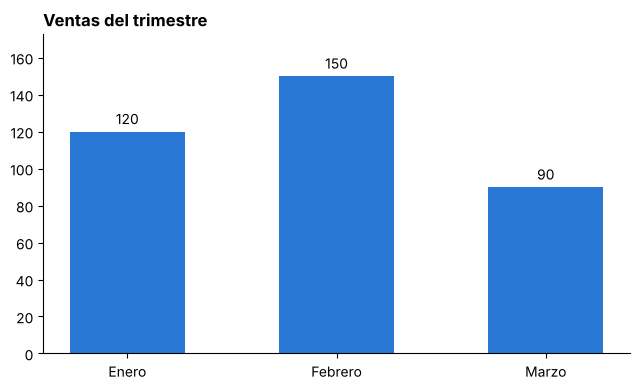

In [ ]:
#@title Tres valores en un gráfico { display-mode: "form" }
#@markdown Escribe un nombre y un valor para cada dato, elige el tipo de gráfico y pulsa ejecutar.
titulo = "Ventas del trimestre" #@param {type:"string"}
nombre_1 = "Enero" #@param {type:"string"}
valor_1 = 120 #@param {type:"number"}
nombre_2 = "Febrero" #@param {type:"string"}
valor_2 = 150 #@param {type:"number"}
nombre_3 = "Marzo" #@param {type:"string"}
valor_3 = 90 #@param {type:"number"}
tipo_grafico = "barras" #@param ["barras", "líneas", "torta"]

import matplotlib.pyplot as plt

nombres = [nombre_1, nombre_2, nombre_3]
valores = [valor_1, valor_2, valor_3]
AZUL = "#2a78d6"
COLORES = ["#2a78d6", "#eb6834", "#1baf7a"]

if tipo_grafico == "torta" and (min(valores) < 0 or sum(valores) == 0):
    print("La torta necesita valores positivos. Cambia los valores o el tipo de gráfico.")
else:
    print(f"Total: {sum(valores):g}   Promedio: {sum(valores) / 3:.1f}   Mayor: {nombres[valores.index(max(valores))]}")
    fig, ax = plt.subplots(figsize=(6.5, 4))
    if tipo_grafico == "barras":
        barras = ax.bar(nombres, valores, color=AZUL, width=0.55)
        ax.bar_label(barras, fmt="%g", padding=3)
    elif tipo_grafico == "líneas":
        ax.plot(nombres, valores, color=AZUL, marker="o", linewidth=2)
        for n, v in zip(nombres, valores):
            ax.annotate(f"{v:g}", (n, v), textcoords="offset points", xytext=(0, 8), ha="center")
    else:
        ax.pie(valores, labels=nombres, colors=COLORES, autopct="%1.0f%%",
               startangle=90, counterclock=False,
               wedgeprops={"edgecolor": "white", "linewidth": 2})
    ax.set_title(titulo, loc="left", fontweight="bold")
    if tipo_grafico != "torta":
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_ylim(min(0, min(valores) * 1.1), max(valores) * 1.15 if max(valores) > 0 else 1)
    plt.tight_layout()
    plt.show()

## Nivel 4. Un dashboard solo para mirar

Aquí **la persona no escribe nada**: el autor (tú) carga los datos, los trata y deja listo lo que se va a mostrar. Por eso hay dos celdas:

1. **Preparación (la hace el autor).** Cargar, limpiar y resumir los datos. Esta celda no tiene que ser bonita; es tu trabajo con pandas.
2. **Dashboard (lo que ve el usuario).** Usa solo los resultados de la celda anterior: tarjetas con las cifras clave, tres gráficos en una sola figura y una tabla con estilo.

**Recursos nuevos:** tarjetas en HTML, `plt.subplots(1, 3)` para varios gráficos y `resumen.style` para la tabla.

In [ ]:
# --- PREPARACIÓN (autor): datos inventados de ventas por mes y sede ---
import pandas as pd

meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun"]
datos = pd.DataFrame({
    "mes":   meses * 3,
    "sede":  ["Norte"] * 6 + ["Sur"] * 6 + ["Centro"] * 6,
    "ventas": [92, 98, 105, 110, 118, 126,
               85, 80, 88, 91, 95, 99,
               120, 118, 126, 131, 128, 140],
})
meta_mensual = {"Norte": 100, "Sur": 95, "Centro": 125}

# Ventas por mes y sede (columnas = sedes)
por_mes = datos.pivot_table(index="mes", columns="sede", values="ventas", aggfunc="sum").loc[meses]

# Resumen por sede
resumen = datos.groupby("sede").agg(total=("ventas", "sum"), promedio=("ventas", "mean"), maximo=("ventas", "max"))
resumen["meta"] = pd.Series(meta_mensual) * len(meses)
resumen["cumplimiento"] = resumen["total"] / resumen["meta"]
resumen = resumen.sort_values("total", ascending=False)
resumen

,total,promedio,maximo,meta,cumplimiento
sede,,,,,
Centro,763,127.166667,140,750,1.017333
Norte,649,108.166667,126,600,1.081667
Sur,538,89.666667,99,570,0.943860


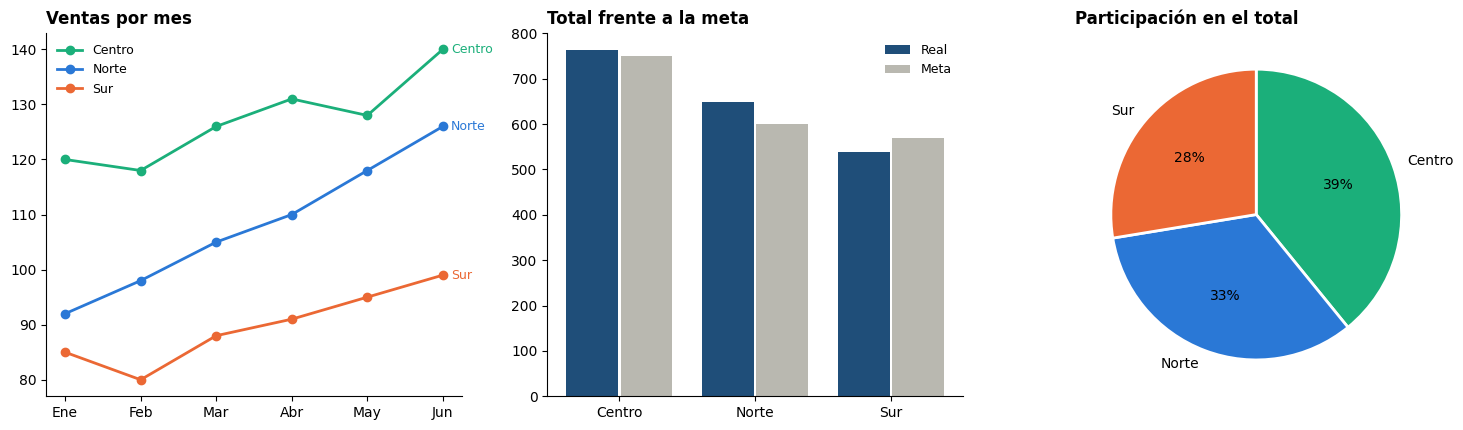

,total,promedio,maximo,meta,cumplimiento
sede,,,,,
Centro,763,127.2,140,750,102%
Norte,649,108.2,126,600,108%
Sur,538,89.7,99,570,94%


In [ ]:
#@title Dashboard de ventas { display-mode: "form" }
from IPython.display import display, HTML
import matplotlib.pyplot as plt

COLOR_SEDE = {"Norte": "#2a78d6", "Sur": "#eb6834", "Centro": "#1baf7a"}   # cada sede conserva su color
GRIS = "#b9b8b0"

# ---- Cifras clave
total = resumen["total"].sum()
cumpl_global = total / resumen["meta"].sum()
mejor_sede = resumen["total"].idxmax()
mejor_mes = por_mes.sum(axis=1).idxmax()

def tarjeta(titulo, valor, detalle=""):
    return f"""
    <div style="flex:1; min-width:150px; background:#f5f7fa; border-top:4px solid #2a78d6; border-radius:6px; padding:10px 14px; color:#0b0b0b">
      <div style="font-size:12px; color:#52514e">{titulo}</div>
      <div style="font-size:26px; font-weight:bold">{valor}</div>
      <div style="font-size:12px; color:#52514e">{detalle}</div>
    </div>"""

display(HTML(f"""
<div style="font-family:Arial,sans-serif">
  <div style="font-size:22px; font-weight:bold; color:#1F4E79">Ventas por sede, enero a junio</div>
  <div style="font-size:13px; color:#52514e; margin-bottom:10px">Datos de ejemplo (inventados)</div>
  <div style="display:flex; gap:12px; flex-wrap:wrap">
    {tarjeta("Ventas totales", f"{total:,.0f}")}
    {tarjeta("Cumplimiento de la meta", f"{cumpl_global:.0%}")}
    {tarjeta("Mejor sede", mejor_sede, f"{resumen.loc[mejor_sede, 'total']:,.0f} en ventas")}
    {tarjeta("Mes más fuerte", mejor_mes)}
  </div>
</div>
"""))

# ---- Tres gráficos en una figura
fig, axs = plt.subplots(1, 3, figsize=(15, 4.4))

for sede in por_mes.columns:                                   # 1) tendencia por mes
    axs[0].plot(por_mes.index, por_mes[sede], color=COLOR_SEDE[sede], marker="o", linewidth=2, label=sede)
    axs[0].annotate(sede, (por_mes.index[-1], por_mes[sede].iloc[-1]), textcoords="offset points",
                    xytext=(6, 0), va="center", color=COLOR_SEDE[sede], fontsize=9)
axs[0].set_title("Ventas por mes", loc="left", fontweight="bold")
axs[0].spines[["top", "right"]].set_visible(False)
axs[0].legend(frameon=False, loc="upper left", fontsize=9)

x = range(len(resumen))                                         # 2) total frente a la meta
axs[1].bar([i - 0.2 for i in x], resumen["total"], width=0.38, color="#1F4E79", label="Real")
axs[1].bar([i + 0.2 for i in x], resumen["meta"], width=0.38, color=GRIS, label="Meta")
axs[1].set_xticks(list(x))
axs[1].set_xticklabels(resumen.index)
axs[1].set_title("Total frente a la meta", loc="left", fontweight="bold")
axs[1].spines[["top", "right"]].set_visible(False)
axs[1].legend(frameon=False, fontsize=9)

axs[2].pie(resumen["total"], labels=resumen.index, colors=[COLOR_SEDE[s] for s in resumen.index],   # 3) participación
           autopct="%1.0f%%", startangle=90, counterclock=False, wedgeprops={"edgecolor": "white", "linewidth": 2})
axs[2].set_title("Participación en el total", loc="left", fontweight="bold")

plt.tight_layout()
plt.show()

# ---- Tabla con estilo
display(resumen.style
        .format({"total": "{:,.0f}", "promedio": "{:.1f}", "maximo": "{:,.0f}", "meta": "{:,.0f}", "cumplimiento": "{:.0%}"})
        .background_gradient(subset=["cumplimiento"], cmap="Blues")
        .set_caption("Resumen por sede"))

In [4]:
#@title Calculadora varia
#@markdown Seleccione la operación
numero1 = 10 #@param {type: "number"}
numero2 = 15 #@param {type: "number"}
operacion = "multiplicación" #@param ["suma", "resta", "multiplicación", "división"]

if operacion == "suma":
  resultado = numero1 + numero2
elif operacion == "resta":
  resultado = numero1 - numero2
elif operacion == "multiplicación":
  resultado = numero1 * numero2
elif operacion == "división":
  resultado = numero1 / numero2

from IPython.display import display, HTML

display(HTML(f"""
<div style="
  font-family: 'Segoe UI', -apple-system, BlinkMacSystemFont, Roboto, sans-serif;
  background: linear-gradient(135deg, #667eea 0%, #764ba2 100%);
  border-radius: 16px;
  padding: 24px;
  max-width: 340px;
  color: #ffffff;
  box-shadow: 0 10px 20px rgba(118, 75, 162, 0.3);
  position: relative;
  overflow: hidden;
">
  <div style="
    position: absolute;
    top: -20px;
    right: -20px;
    width: 80px;
    height: 80px;
    background: rgba(255,255,255,0.1);
    border-radius: 50%;
  "></div>
  <div style="
    font-size: 11px;
    font-weight: 700;
    text-transform: uppercase;
    color: rgba(255, 255, 255, 0.8);
    letter-spacing: 1.5px;
  ">
    Resultado · {operacion}
  </div>
  <div style="
    font-size: 42px;
    font-weight: 800;
    margin-top: 8px;
    line-height: 1;
    text-shadow: 0 2px 4px rgba(0,0,0,0.15);
  ">
    {resultado:,.2f}
  </div>
  <div style="
    font-size: 12px;
    color: rgba(255, 255, 255, 0.9);
    margin-top: 14px;
    border-top: 1px solid rgba(255, 255, 255, 0.2);
    padding-top: 10px;
  ">
    Valores ingresados: <b>{numero1}</b> y <b>{numero2}</b>
  </div>
</div>
"""))

## Tu turno

1. **Nivel 1:** agrega una lista desplegable con la operación (`suma`, `resta`, `multiplicación`, `división`). Se escribe con una línea como `operacion = "suma" #@param ["suma", "resta", "multiplicación", "división"]`. Cuida la división entre cero.
2. **Nivel 4:** cambia los datos de la celda de preparación por los de tu proyecto, ejecuta todo y mira cómo se actualiza el dashboard.
3. **Mejóralo con un prompt:** pídele a Gemini que mejore solo la parte visual (colores, tamaños, orden de las tarjetas) sin tocar el cálculo.
4. **Publícalo:** ejecuta todo desde cero, guarda con *Archivo → Guardar una copia en GitHub* y agrega el botón de Colab al README de tu repositorio.

*Recuerda: el repositorio es público. No subas claves ni datos privados.*